# 1. Scenario - 2 Past Power + Past Exogenous inputs


Imports, paths, artifact locations, and configuration variables are defined in the next cell.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model

artifact_dir = Path(r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks")
model_path = artifact_dir / "scenario1_encoder_decoder.keras"
scaler_path = artifact_dir / "scenario1_scaler.joblib"
results_path = artifact_dir / "scenario1_test_results.npz"

W_TRAIN = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Training.xlsx"
W_VALIDATION = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Val.xlsx"
W_TEST = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Test.xlsx"

# 2. Load Dataset

Load the existing chronological Excel datasets and inspect their row/day counts. No raw data or split files are changed.

In [2]:
def load_data(train_path, validation_path, test_path):
    """Load the three existing chronological Excel splits without re-splitting."""
    train = pd.read_excel(train_path)
    validation = pd.read_excel(validation_path)
    test = pd.read_excel(test_path)

    for split in (train, validation, test):
        split['TimeStamp'] = pd.to_datetime(split['TimeStamp'])
        split['Date'] = split['TimeStamp'].dt.date
        split.sort_values('TimeStamp', inplace=True)
        split.reset_index(drop=True, inplace=True)

    return train, validation, test


W_TRAIN = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Training.xlsx"
W_VALIDATION = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Val.xlsx"
W_TEST = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Test.xlsx"

train, validation, test = load_data(W_TRAIN, W_VALIDATION, W_TEST)

print('Train days      :', train['Date'].nunique())
print('Validation days :', validation['Date'].nunique())
print('Test days       :', test['Date'].nunique())
print()
print('Train rows      :', len(train))
print('Validation rows :', len(validation))
print('Test rows       :', len(test))

Train days      : 86
Validation days : 30
Test days       : 7

Train rows      : 8256
Validation rows : 2880
Test rows       : 672


# 3. Train / Validation / Test Split

The notebook uses the existing chronological Excel splits without re-splitting or shuffling the datasets.

# 4. Revision Sample Creation

Put the existing revision lengths, target length, padded input length, sample creator, and train/validation/test sample creation in this section.

In [5]:
import numpy as np
import pandas as pd

# 1. Scenario 2 configuration
REVISION_LENGTHS = {
    "R0": 32,
    "R1": 50,
    "R2": 64,
    "R3": 82,
}

BLOCKS_PER_DAY = 96
TARGET_LENGTH = BLOCKS_PER_DAY
PADDED_INPUT_LENGTH = max(REVISION_LENGTHS.values())
POWER_COLUMN = "Act. Power (MW)"

# Keep the measured channels in the order used by the recovered notebook.
MEASURED_FEATURES = [
    POWER_COLUMN,
    "W-GHI (W/m2)",
    "W-MODT- (°C)",
    "W-AMBT (°C)",
    "W-WSPD (m/s)",
]

INPUT_FEATURES = MEASURED_FEATURES + ["sin(time)", "cos(time)"]
N_INPUT_FEATURES = len(INPUT_FEATURES)


# 2. Create unscaled, unpadded D → D+1 samples
def create_revision_samples(split, split_name="Split"):
    """Use day D's history to predict all 96 power values on day D+1."""
    data = split.copy()

    required = ["TimeStamp", *MEASURED_FEATURES]
    missing = [column for column in required if column not in data.columns]
    if missing:
        raise ValueError(f"{split_name}: missing columns: {missing}")

    data["TimeStamp"] = pd.to_datetime(data["TimeStamp"], errors="raise")
    data = data.sort_values("TimeStamp").reset_index(drop=True)
    timestamps = data["TimeStamp"]

    if timestamps.isna().any() or timestamps.duplicated().any():
        raise ValueError(f"{split_name}: found missing or duplicate timestamps.")

    if not timestamps.eq(timestamps.dt.floor("15min")).all():
        raise ValueError(f"{split_name}: timestamps must be on the 15-minute grid.")

    for column in MEASURED_FEATURES:
        data[column] = pd.to_numeric(data[column], errors="raise")

    block_index = timestamps.dt.hour * 4 + timestamps.dt.minute // 15
    phase = 2.0 * np.pi * block_index / BLOCKS_PER_DAY
    data["sin(time)"] = np.sin(phase)
    data["cos(time)"] = np.cos(phase)

    day_groups = {
        day: rows.set_index("TimeStamp")
        for day, rows in data.groupby(timestamps.dt.normalize(), sort=True)
    }

    X, y, revision_labels, sample_dates = [], [], [], []
    revision_indices = {revision: [] for revision in REVISION_LENGTHS}

    for day, day_data in day_groups.items():
        next_day = day + pd.DateOffset(days=1)
        if next_day not in day_groups:
            continue

        history_grid = pd.date_range(day, periods=PADDED_INPUT_LENGTH, freq="15min")
        target_grid = pd.date_range(next_day, periods=TARGET_LENGTH, freq="15min")
        target_data = day_groups[next_day]

        if not history_grid.isin(day_data.index).all():
            raise ValueError(f"{split_name}: incomplete history on {day.date()}.")

        if not target_data.index.equals(target_grid):
            raise ValueError(f"{split_name}: incomplete target day {next_day.date()}.")

        history = day_data.loc[history_grid, INPUT_FEATURES].to_numpy(dtype=np.float32)
        target = target_data.loc[target_grid, POWER_COLUMN].to_numpy(dtype=np.float32)

        if not np.isfinite(history).all() or not np.isfinite(target).all():
            raise ValueError(f"{split_name}: nonfinite values in pair {day.date()} → {next_day.date()}.")

        for revision, length in REVISION_LENGTHS.items():
            revision_indices[revision].append(len(X))
            X.append(history[:length].copy())
            y.append(target.copy())
            revision_labels.append(revision)
            sample_dates.append(next_day.date())

    if not X:
        raise ValueError(f"{split_name}: no valid consecutive-day pairs found.")

    return (
        X,
        np.stack(y),
        np.asarray(revision_labels),
        revision_indices,
        np.asarray(sample_dates),
    )


# 3. Build training and validation samples within their original splits.
X_train, y_train, revision_labels_train, revision_indices_train, dates_train = (
    create_revision_samples(train, "Train")
)

X_validation, y_validation, revision_labels_validation, revision_indices_validation, dates_validation = (
    create_revision_samples(validation, "Validation")
)


# 4. Include February 7 as input history for the first test forecast.
test_days = pd.date_range("2026-02-08", "2026-02-14", freq="D")
history_date = (test_days[0] - pd.Timedelta(days=1)).date()

validation_times = pd.to_datetime(validation["TimeStamp"], errors="raise")
history_rows = validation.loc[validation_times.dt.date == history_date]

if history_rows.empty:
    raise ValueError(f"Validation is missing the history day {history_date}.")

test_with_history = pd.concat([history_rows, test], ignore_index=True)

X_test, y_test, revision_labels_test, revision_indices_test, dates_test = (
    create_revision_samples(test_with_history, "Test")
)


# 5. Verify all seven test dates and all four revisions.
expected_pairs = pd.MultiIndex.from_product(
    [test_days.date, list(REVISION_LENGTHS)],
    names=["Target date", "Revision"],
)
actual_pairs = pd.MultiIndex.from_arrays(
    [dates_test, revision_labels_test],
    names=["Target date", "Revision"],
)

if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError("Expected one R0–R3 sample per test day from February 8–14.")

train_dates = set(dates_train)
validation_dates = set(dates_validation)
test_dates_set = set(dates_test)

if (train_dates & validation_dates or train_dates & test_dates_set
        or validation_dates & test_dates_set):
    raise ValueError("Target dates overlap between splits.")

revision_info = {
    "lengths": REVISION_LENGTHS.copy(),
    "train": revision_indices_train,
    "validation": revision_indices_validation,
    "test": revision_indices_test,
}

for name, targets, dates in (
    ("Train", y_train, dates_train),
    ("Validation", y_validation, dates_validation),
    ("Test", y_test, dates_test),
):
    print(f"{name:<11} | {len(set(dates)):2} target days | y shape: {targets.shape}")

Train       | 85 target days | y shape: (340, 96)
Validation  | 29 target days | y shape: (116, 96)
Test        |  7 target days | y shape: (28, 96)


# 5. Preprocessing and Scaling

This section preserves the existing `MinMaxScaler`, time features, padding, and scaled input creation.

In [6]:
from sklearn.preprocessing import MinMaxScaler

# INPUT_FEATURES ends with sin(time), cos(time).
SCALED_INPUT_FEATURES = INPUT_FEATURES[:-2]
N_SCALED_INPUT_FEATURES = len(SCALED_INPUT_FEATURES)


def finite_training_values(columns):
    """Read numeric training values and reject missing/infinite values."""
    values = (
        train.loc[:, columns]
        .apply(pd.to_numeric, errors="raise")
        .to_numpy(dtype=np.float64)
    )

    if values.shape[0] == 0:
        raise ValueError("The training dataframe is empty.")

    if not np.isfinite(values).all():
        raise ValueError(
            f"Training columns {columns} contain missing or infinite "
            "values. Resolve these in preprocessing before scaling."
        )

    return values


# Fit on raw training rows, avoiding repeated observations from
# overlapping R0/R1/R2/R3 histories.
input_scaler = MinMaxScaler(feature_range=(0.0, 1.0))
input_scaler.fit(finite_training_values(SCALED_INPUT_FEATURES))

# Separate scaler for the 96 next-day power targets.
target_scaler = MinMaxScaler(feature_range=(0.0, 1.0))
target_scaler.fit(finite_training_values([POWER_COLUMN]))


def scale_histories(histories):
    """Scale real observations only; preserve time features."""
    scaled_histories = []

    for history in histories:
        scaled = np.array(history, dtype=np.float32, copy=True)

        if scaled.ndim != 2 or scaled.shape[1] != N_INPUT_FEATURES:
            raise ValueError(
                f"Expected history shape (timesteps, {N_INPUT_FEATURES}); "
                f"received {scaled.shape}."
            )

        if not np.isfinite(scaled).all():
            raise ValueError("History contains missing or infinite values.")

        scaled[:, :N_SCALED_INPUT_FEATURES] = (
            input_scaler.transform(
                scaled[:, :N_SCALED_INPUT_FEATURES]
            ).astype(np.float32)
        )

        # Last two columns remain sin(time), cos(time).
        scaled_histories.append(scaled)

    return scaled_histories


def scale_targets(targets):
    """Apply one power scale consistently across all 96 blocks."""
    targets = np.asarray(targets, dtype=np.float32)

    if targets.ndim != 2 or targets.shape[1] != TARGET_LENGTH:
        raise ValueError(
            f"Expected target shape (samples, {TARGET_LENGTH}); "
            f"received {targets.shape}."
        )

    if not np.isfinite(targets).all():
        raise ValueError("Targets contain missing or infinite values.")

    return target_scaler.transform(
        targets.reshape(-1, 1)
    ).reshape(targets.shape).astype(np.float32)


# Still variable-length lists: padding comes in the next cell.
X_train_scaled_unpadded = scale_histories(X_train)
X_validation_scaled_unpadded = scale_histories(X_validation)
X_test_scaled_unpadded = scale_histories(X_test)

y_train_scaled = scale_targets(y_train)
y_validation_scaled = scale_targets(y_validation)
y_test_scaled = scale_targets(y_test)

print("Scaled input columns:", SCALED_INPUT_FEATURES)
print("Time columns:", INPUT_FEATURES[-2:])

for name, histories, targets in (
    ("Train", X_train_scaled_unpadded, y_train_scaled),
    ("Validation", X_validation_scaled_unpadded, y_validation_scaled),
    ("Test", X_test_scaled_unpadded, y_test_scaled),
):
    print(f"{name:<11} | {len(histories):3} histories | targets {targets.shape}")

assert len(X_test_scaled_unpadded) == 28
assert y_test_scaled.shape == (28, TARGET_LENGTH)

Scaled input columns: ['Act. Power (MW)', 'W-GHI (W/m2)', 'W-MODT- (°C)', 'W-AMBT (°C)', 'W-WSPD (m/s)']
Time columns: ['sin(time)', 'cos(time)']
Train       | 340 histories | targets (340, 96)
Validation  | 116 histories | targets (116, 96)
Test        |  28 histories | targets (28, 96)


In [7]:
PAD_VALUE = -1.0


def time_features(block_indices):
    """Zero-based positions: 0 = 00:00, 95 = 23:45."""
    block_indices = np.asarray(block_indices, dtype=np.float64)
    phase = 2.0 * np.pi * block_indices / BLOCKS_PER_DAY

    return np.column_stack(
        (np.sin(phase), np.cos(phase))
    ).astype(np.float32)


def pad_revision_samples(
    scaled_histories,
    revision_labels,
    split_name="Split",
):
    """Post-pad already-scaled histories without changing real values."""
    labels = np.asarray(revision_labels)

    if labels.ndim != 1 or len(scaled_histories) != len(labels):
        raise ValueError(
            f"{split_name}: histories and revision labels do not match."
        )

    unknown_labels = set(labels.tolist()) - set(REVISION_LENGTHS)
    if unknown_labels:
        raise ValueError(
            f"{split_name}: unknown revisions: {unknown_labels}"
        )

    X_padded = np.full(
        (
            len(scaled_histories),
            PADDED_INPUT_LENGTH,
            N_INPUT_FEATURES,
        ),
        PAD_VALUE,
        dtype=np.float32,
    )

    for sample_index, (history, revision) in enumerate(
        zip(scaled_histories, labels)
    ):
        history = np.asarray(history, dtype=np.float32)
        real_length = REVISION_LENGTHS[revision]

        expected_shape = (real_length, N_INPUT_FEATURES)
        if history.shape != expected_shape:
            raise ValueError(
                f"{split_name}, sample {sample_index}, {revision}: "
                f"expected {expected_shape}, received {history.shape}."
            )

        if not np.isfinite(history).all():
            raise ValueError(
                f"{split_name}, sample {sample_index}: "
                "nonfinite history values."
            )

        expected_time = time_features(np.arange(real_length))
        if not np.allclose(
            history[:, -2:],
            expected_time,
            atol=1e-6,
            rtol=0.0,
        ):
            raise ValueError(
                f"{split_name}, sample {sample_index}: "
                "time features do not match the expected block positions."
            )

        # Masking must never discard a real observation.
        if np.any(np.all(history == PAD_VALUE, axis=1)):
            raise ValueError(
                f"{split_name}, sample {sample_index}: "
                "a real timestep matches the padding sentinel."
            )

        X_padded[sample_index, :real_length, :] = history

    # Verify the exact mask for every sample, including unpadded R3.
    real_lengths = np.asarray(
        [REVISION_LENGTHS[revision] for revision in labels]
    )
    expected_padding = (
        np.arange(PADDED_INPUT_LENGTH)[None, :]
        >= real_lengths[:, None]
    )
    actual_padding = np.all(X_padded == PAD_VALUE, axis=-1)

    if not np.array_equal(actual_padding, expected_padding):
        raise ValueError(f"{split_name}: incorrect padding mask.")

    return X_padded


# Use histories already scaled in the preceding cell.
X_train_scaled = pad_revision_samples(
    X_train_scaled_unpadded,
    revision_labels_train,
    "Train",
)

X_validation_scaled = pad_revision_samples(
    X_validation_scaled_unpadded,
    revision_labels_validation,
    "Validation",
)

X_test_scaled = pad_revision_samples(
    X_test_scaled_unpadded,
    revision_labels_test,
    "Test",
)


# y_*_scaled already exists from the preceding scaling cell.
for split_name, X_scaled, y_scaled, labels in (
    (
        "Train",
        X_train_scaled,
        y_train_scaled,
        revision_labels_train,
    ),
    (
        "Validation",
        X_validation_scaled,
        y_validation_scaled,
        revision_labels_validation,
    ),
    (
        "Test",
        X_test_scaled,
        y_test_scaled,
        revision_labels_test,
    ),
):
    assert X_scaled.shape == (
        len(labels),
        PADDED_INPUT_LENGTH,
        N_INPUT_FEATURES,
    )
    assert y_scaled.shape == (len(labels), TARGET_LENGTH)
    assert X_scaled.dtype == np.float32
    assert y_scaled.dtype == np.float32
    assert np.isfinite(X_scaled).all()
    assert np.isfinite(y_scaled).all()

    print(
        f"{split_name}: "
        f"X shape={X_scaled.shape}, y shape={y_scaled.shape}"
    )

    for revision, real_length in REVISION_LENGTHS.items():
        count = np.count_nonzero(labels == revision)
        last_position = real_length - 1
        last_time = (
            f"{last_position // 4:02d}:"
            f"{(last_position % 4) * 15:02d}"
        )

        print(
            f"  {revision}: {count} samples | "
            f"blocks 1–{real_length}, 00:00–{last_time} | "
            f"{real_length} real + "
            f"{PADDED_INPUT_LENGTH - real_length} padded timesteps"
        )

print("\nInput feature order:", INPUT_FEATURES)
print("Checks passed: seven features, aligned times, correct padding.")

Train: X shape=(340, 82, 7), y shape=(340, 96)
  R0: 85 samples | blocks 1–32, 00:00–07:45 | 32 real + 50 padded timesteps
  R1: 85 samples | blocks 1–50, 00:00–12:15 | 50 real + 32 padded timesteps
  R2: 85 samples | blocks 1–64, 00:00–15:45 | 64 real + 18 padded timesteps
  R3: 85 samples | blocks 1–82, 00:00–20:15 | 82 real + 0 padded timesteps
Validation: X shape=(116, 82, 7), y shape=(116, 96)
  R0: 29 samples | blocks 1–32, 00:00–07:45 | 32 real + 50 padded timesteps
  R1: 29 samples | blocks 1–50, 00:00–12:15 | 50 real + 32 padded timesteps
  R2: 29 samples | blocks 1–64, 00:00–15:45 | 64 real + 18 padded timesteps
  R3: 29 samples | blocks 1–82, 00:00–20:15 | 82 real + 0 padded timesteps
Test: X shape=(28, 82, 7), y shape=(28, 96)
  R0: 7 samples | blocks 1–32, 00:00–07:45 | 32 real + 50 padded timesteps
  R1: 7 samples | blocks 1–50, 00:00–12:15 | 50 real + 32 padded timesteps
  R2: 7 samples | blocks 1–64, 00:00–15:45 | 64 real + 18 padded timesteps
  R3: 7 samples | blocks 1

# 6. Reproducibility

This section must run before model creation or training.

In [8]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")

Reproducibility configured with seed 42.


# 7. Model Architecture

This section contains only the existing encoder-decoder model definition.

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Masking, SimpleRNN, Dense, Concatenate,
    RepeatVector, TimeDistributed, Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping

# Scenario 2: past power, four past weather measurements, and two time features.
SEED = 42
MASK_VALUE = PAD_VALUE
N_HISTORY_FEATURES = X_train_scaled.shape[-1]
N_FUTURE_EXOG = 0  # Next-day input contains only sin(time) and cos(time).

assert N_HISTORY_FEATURES == 7, "Scenario 2 expects seven history channels."


def build_model(n_future_exog):
    """Build the shared encoder-decoder SimpleRNN architecture."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_input = Input(
        shape=(PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        name="encoder_input",
    )
    masked_encoder_input = Masking(
        mask_value=MASK_VALUE,
        name="encoder_masking",
    )(encoder_input)
    encoder_context = SimpleRNN(
        64,
        name="encoder_rnn",
    )(masked_encoder_input)

    future_input = Input(
        shape=(TARGET_LENGTH, n_future_exog + 2),
        name="future_input",
    )
    repeated_context = RepeatVector(
        TARGET_LENGTH,
        name="repeat_context",
    )(encoder_context)
    decoder_input = Concatenate(
        axis=-1,
        name="decoder_features",
    )([repeated_context, future_input])

    decoder_sequence = SimpleRNN(
        64,
        return_sequences=True,
        name="decoder_rnn",
    )(decoder_input)
    block_predictions = TimeDistributed(
        Dense(1),
        name="block_prediction",
    )(decoder_sequence)
    forecast = Reshape(
        (TARGET_LENGTH,),
        name="forecast",
    )(block_predictions)

    model = Model(
        inputs=[encoder_input, future_input],
        outputs=forecast,
    )
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"],
    )

    assert model.input_shape == [
        (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        (None, TARGET_LENGTH, n_future_exog + 2),
    ]
    assert model.output_shape == (None, TARGET_LENGTH)

    return model


model = build_model(N_FUTURE_EXOG)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 82, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 82, 7)     │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_masking     │ (None, 82, 7)     │          0 │ encoder_input[0]… │
│ (Masking)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 82)        │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_rnn         │ (None, 64)        │      4,608 │ encoder_masking[… │
│ (SimpleRNN)         │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 96, 64)    │          0 │ encoder_rnn[0][0] │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future_input        │ (None, 96, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_features    │ (None, 96, 66)    │          0 │ repeat_context[0… │
│ (Concatenate)       │                   │            │ future_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_rnn         │ (None, 96, 64)    │      8,384 │ decoder_features… │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_prediction    │ (None, 96, 1)     │         65 │ decoder_rnn[0][0] │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast (Reshape)  │ (None, 96)        │          0 │ block_prediction… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 13,057 (51.00 KB)

 Trainable params: 13,057 (51.00 KB)

 Non-trainable params: 0 (0.00 B)

# 8. Model Training

**RUN ONLY WHEN TRAINING THE MODEL**  
**DO NOT RUN FOR DEMO**

In [11]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping


# 1. Prepare the next-day clock inputs.
future_time = time_features(np.arange(TARGET_LENGTH))

def make_future_time_inputs(n_samples):
    return np.repeat(future_time[None, :, :], n_samples, axis=0).astype(np.float32)

future_time_train = make_future_time_inputs(len(X_train_scaled))
future_time_validation = make_future_time_inputs(len(X_validation_scaled))
future_time_test = make_future_time_inputs(len(X_test_scaled))

for name, X, clock, y in (
    ("Train", X_train_scaled, future_time_train, y_train_scaled),
    ("Validation", X_validation_scaled, future_time_validation, y_validation_scaled),
    ("Test", X_test_scaled, future_time_test, y_test_scaled),
):
    assert X.shape == (len(y), PADDED_INPUT_LENGTH, N_INPUT_FEATURES)
    assert clock.shape == (len(y), TARGET_LENGTH, 2)
    assert y.shape == (len(y), TARGET_LENGTH)
    print(f"{name}: history={X.shape}, future time={clock.shape}, targets={y.shape}")

assert y_test_scaled.shape == (28, 96)


# 2. Compute the same night mask used in Scenario 1.
complete_days = []
for date, rows in train.groupby("Date", sort=True):
    rows = rows.sort_values("TimeStamp")
    expected_times = pd.date_range(date, periods=BLOCKS_PER_DAY, freq="15min")

    if pd.DatetimeIndex(rows["TimeStamp"]).equals(expected_times):
        power = rows[POWER_COLUMN].to_numpy(dtype=np.float32)
        if not np.isfinite(power).all():
            raise ValueError(f"Missing or infinite training power on {date}.")
        complete_days.append(power)

if not complete_days:
    raise ValueError("No complete raw training days found for the night mask.")

active_fraction = (np.stack(complete_days) > 0.1).mean(axis=0)
night_mask = active_fraction < 0.10
night_blocks = np.flatnonzero(night_mask)


# 3. Locate the Scenario 2 checkpoint.
artifact_dir = Path(W_TRAIN).parent.parent / "Saved_Models" / "Scenario_2"
artifact_dir.mkdir(parents=True, exist_ok=True)

model_path = artifact_dir / "scenario2_encoder_decoder.keras"
scaler_path = artifact_dir / "scenario2_preprocessing.joblib"
legacy_dir = Path.cwd() / "artifacts" / "scenario2"

checkpoint_dir = None
for folder in (artifact_dir, legacy_dir):
    has_model = (folder / model_path.name).is_file()
    has_metadata = (folder / scaler_path.name).is_file()

    if has_model != has_metadata:
        raise FileNotFoundError(f"Incomplete Scenario 2 checkpoint in {folder}.")
    if has_model:
        checkpoint_dir = folder
        break


# 4. Load an existing checkpoint or train once.
if checkpoint_dir is not None:
    saved = joblib.load(checkpoint_dir / scaler_path.name)

    # Check the meaning and order of the seven input channels before prediction.
    if list(saved["input_features"]) != list(INPUT_FEATURES):
        raise ValueError("Saved feature order differs from this notebook's INPUT_FEATURES.")
    if saved["revision_lengths"] != REVISION_LENGTHS or saved["pad_value"] != PAD_VALUE:
        raise ValueError("Saved revision lengths or padding value differ from this notebook.")

    # The arrays were scaled in the preceding cell, so their transformations must match.
    for key, current in (("input_scaler", input_scaler), ("target_scaler", target_scaler)):
        stored = saved[key]
        if not (
            np.array_equal(stored.scale_, current.scale_)
            and np.array_equal(stored.min_, current.min_)
        ):
            raise ValueError(f"{key} differs from the scaler used for this checkpoint.")

    model = tf.keras.models.load_model(checkpoint_dir / model_path.name, compile=False)
    if model.input_shape != [
        (None, PADDED_INPUT_LENGTH, N_INPUT_FEATURES),
        (None, TARGET_LENGTH, 2),
    ] or model.output_shape != (None, TARGET_LENGTH):
        raise ValueError("The saved model dimensions differ from the Scenario 2 setup.")

    input_scaler = saved["input_scaler"]
    target_scaler = saved["target_scaler"]
    training_history = saved.get("training_history", {})
    best_epoch = saved.get("best_epoch")

    # Keep the original trained checkpoint intact when moving to the shared layout.
    if checkpoint_dir != artifact_dir:
        from shutil import copy2
        copy2(checkpoint_dir / model_path.name, model_path)

    print(f"Loaded trained model from {checkpoint_dir}")

else:
    early_stopping = EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=15,
        restore_best_weights=True,
    )

    # Uses the fresh Scenario 2 model built in the preceding cell.
    history = model.fit(
        [X_train_scaled, future_time_train],
        y_train_scaled,
        validation_data=(
            [X_validation_scaled, future_time_validation],
            y_validation_scaled,
        ),
        epochs=150,
        batch_size=16,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=1,
    )

    training_history = history.history
    validation_losses = np.asarray(training_history["val_loss"])
    if not np.isfinite(validation_losses).all():
        raise RuntimeError("Nonfinite validation loss. Inspect training before saving.")

    best_epoch = int(np.argmin(validation_losses)) + 1
    model.save(model_path)
    print(f"Trained for {len(history.epoch)} epochs. Best epoch: {best_epoch}.")


# 5. Save the preprocessing used for the seven-day predictions.
preprocessing_artifacts = {
    "input_scaler": input_scaler,
    "target_scaler": target_scaler,
    "input_features": list(INPUT_FEATURES),
    "scaled_input_features": list(SCALED_INPUT_FEATURES),
    "power_column": POWER_COLUMN,
    "revision_lengths": REVISION_LENGTHS.copy(),
    "padded_input_length": PADDED_INPUT_LENGTH,
    "target_length": TARGET_LENGTH,
    "blocks_per_day": BLOCKS_PER_DAY,
    "pad_value": PAD_VALUE,
    "future_time": future_time,
    "night_mask": night_mask,
    "night_blocks": night_blocks,
    "night_power_threshold_mw": 0.1,
    "night_mask_rule": "Fraction above 0.1 MW < 0.10 across complete raw training days",
    "best_epoch": best_epoch,
    "training_history": training_history,
}
joblib.dump(preprocessing_artifacts, scaler_path)

print(f"Model: {model_path}")
print(f"Preprocessing: {scaler_path}")
print(f"Night blocks: {len(night_blocks)} / {TARGET_LENGTH}")

Train: history=(340, 82, 7), future time=(340, 96, 2), targets=(340, 96)
Validation: history=(116, 82, 7), future time=(116, 96, 2), targets=(116, 96)
Test: history=(28, 82, 7), future time=(28, 96, 2), targets=(28, 96)
Loaded trained model from C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Saved_Models\Scenario_2
Model: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Saved_Models\Scenario_2\scenario2_encoder_decoder.keras
Preprocessing: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Saved_Models\Scenario_2\scenario2_preprocessing.joblib
Night blocks: 52 / 96


# 9. Training Evaluation

Training-only loss visualization. **DO NOT RUN FOR DEMO.**

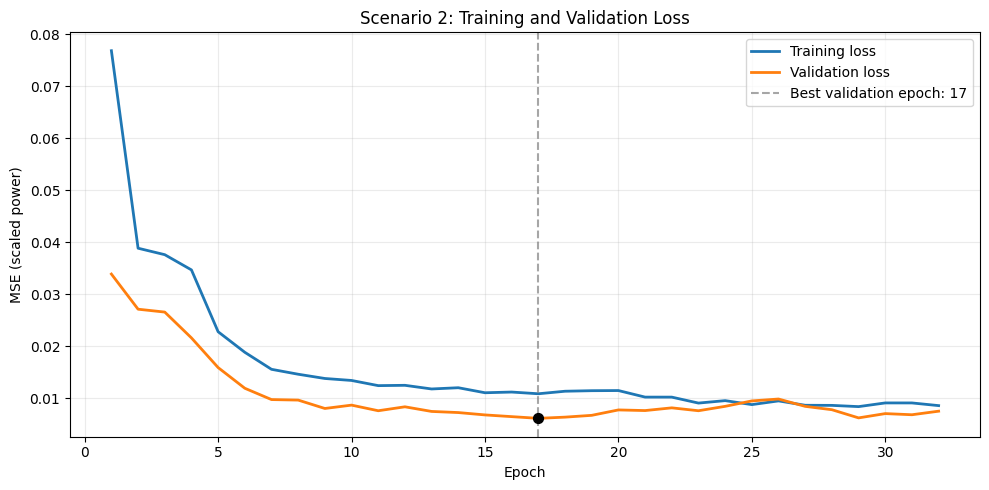

Epochs completed: 32
Best validation epoch: 17
Training MSE at that epoch:   0.010878
Validation MSE at that epoch: 0.006152


In [13]:
import numpy as np
import matplotlib.pyplot as plt

train_loss = np.asarray(training_history.get("loss", []), dtype=float)
val_loss = np.asarray(training_history.get("val_loss", []), dtype=float)

if train_loss.size == 0 or val_loss.size == 0:
    print("Loss history is unavailable for this checkpoint. You can still run predictions.")
elif train_loss.shape != val_loss.shape:
    raise ValueError("Training and validation loss histories have different lengths.")
else:
    epochs = np.arange(1, len(train_loss) + 1)
    best_index = int(np.argmin(val_loss))
    best_epoch = int(epochs[best_index])

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(epochs, train_loss, label="Training loss", linewidth=2)
    ax.plot(epochs, val_loss, label="Validation loss", linewidth=2)
    ax.axvline(
        best_epoch, color="gray", linestyle="--", alpha=0.7,
        label=f"Best validation epoch: {best_epoch}",
    )
    ax.scatter(best_epoch, val_loss[best_index], color="black", s=50, zorder=5)

    ax.set(
        title="Scenario 2: Training and Validation Loss",
        xlabel="Epoch",
        ylabel="MSE (scaled power)",
    )
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()

    print(f"Epochs completed: {len(epochs)}")
    print(f"Best validation epoch: {best_epoch}")
    print(f"Training MSE at that epoch:   {train_loss[best_index]:.6f}")
    print(f"Validation MSE at that epoch: {val_loss[best_index]:.6f}")

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd

scenario = "S2"

# 1. Verify one sample per revision for every target day, February 8–14.
target_dates = pd.DatetimeIndex(dates_test).normalize()
revision_names = {"R0": "Rev0", "R1": "Rev1", "R2": "Rev2", "R3": "Rev3"}
test_days = pd.date_range("2026-02-08", "2026-02-14", freq="D")

expected_pairs = pd.MultiIndex.from_product([test_days, list(revision_names)])
actual_pairs = pd.MultiIndex.from_arrays([target_dates, revision_labels_test])

if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError("Expected one R0–R3 sample for each of the seven test days.")

# 2. Predict and convert back to MW.
predicted_scaled = model.predict([X_test_scaled, future_time_test], verbose=0)
y_actual = np.asarray(y_test)  # Original measured power in MW

expected_shape = (len(expected_pairs), TARGET_LENGTH)
if predicted_scaled.shape != expected_shape or y_actual.shape != expected_shape:
    raise ValueError(f"Expected actual and forecast arrays of shape {expected_shape}.")

y_pred_raw = target_scaler.inverse_transform(
    predicted_scaled.reshape(-1, 1)
).reshape(expected_shape)

if not (np.isfinite(y_actual).all() and np.isfinite(y_pred_raw).all()):
    raise ValueError("Actual or forecast power contains missing or infinite values.")

# 3. Apply the training-derived night mask to a separate forecast array.
night_mask = np.asarray(night_mask, dtype=bool)
if night_mask.shape != (TARGET_LENGTH,):
    raise ValueError(f"Expected a night mask with {TARGET_LENGTH} blocks.")

y_pred = np.maximum(y_pred_raw, 0.0)
y_pred[:, night_mask] = 0.0

# 4. Save one row per revision and target timestamp.
block_offsets = pd.to_timedelta(15 * np.arange(TARGET_LENGTH), unit="min")
target_times = (
    target_dates.repeat(TARGET_LENGTH)
    + np.tile(block_offsets.to_numpy(), len(target_dates))
)

predictions = pd.DataFrame({
    "Revision": np.repeat(
        [revision_names[r] for r in revision_labels_test], TARGET_LENGTH
    ),
    "Target_Time": target_times,
    "Actual_MW": y_actual.ravel(),
    "Forecast_MW": y_pred.ravel(),
}).sort_values(["Revision", "Target_Time"], ignore_index=True)

prediction_dir = Path(W_TRAIN).parent.parent / "Results" / "Predictions"
prediction_dir.mkdir(parents=True, exist_ok=True)
results_path = prediction_dir / f"Winter_Daily_RNN_{scenario}.csv"

predictions.to_csv(results_path, index=False, date_format="%Y-%m-%d %H:%M")
print(f"Saved {len(predictions):,} rows to {results_path}")

Saved 2,688 rows to C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Predictions\Winter_Daily_RNN_S2.csv


# 11. Save Test Results

Save `y_actual`, `y_pred`, `revision_labels_test`, and `dates_test` to `scenario1_test_results.npz`. **RUN AFTER NEW PREDICTIONS ONLY.**

In [11]:
results_path = artifact_dir / "scenario2_test_results.npz"

np.savez(
    results_path,
    y_actual=y_actual,
    y_pred=y_pred,
    revision_labels=revision_labels_test,
    dates_test=dates_test.astype(str),
)

print(f"Results saved to: {results_path}")

Results saved to: c:\Users\yashs\Downloads\artifacts\scenario2\scenario2_test_results.npz


# 12. Results / Demonstration

**DEMO / RESULTS ONLY**  
This section loads the saved `.npz` file and generates presentation plots without loading the model or calling `model.fit()`. It is safe to run after restarting the kernel.

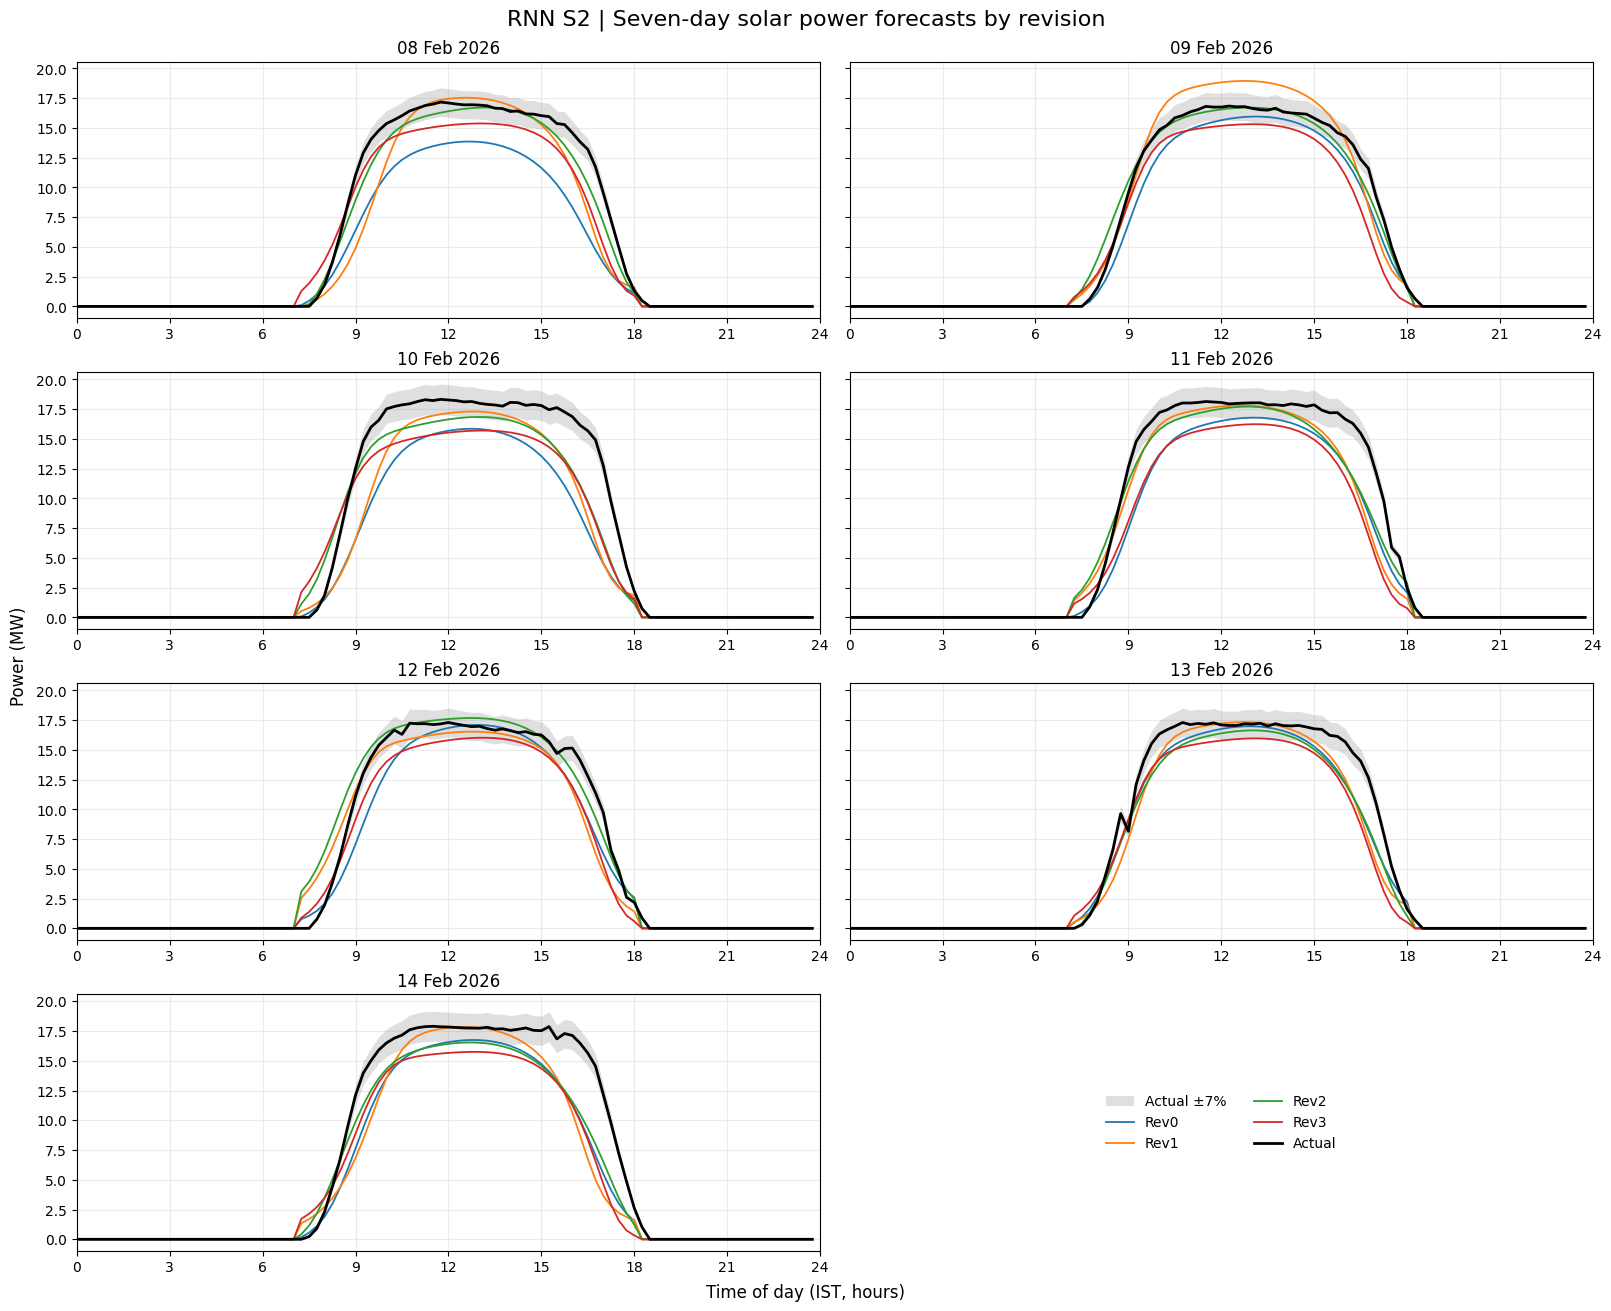

In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator

# 1. Read this scenario's saved predictions.
scenario = "S2"
prediction_dir = Path(W_TRAIN).parent.parent / "Results" / "Predictions"
results_path = prediction_dir / f"Winter_Daily_RNN_{scenario}.csv"
data = pd.read_csv(results_path, parse_dates=["Target_Time"])

revision_colors = {
    "Rev0": "tab:blue",
    "Rev1": "tab:orange",
    "Rev2": "tab:green",
    "Rev3": "tab:red",
}
revisions = list(revision_colors)
test_days = pd.date_range("2026-02-08", "2026-02-14", freq="D")
expected_times = pd.date_range(test_days[0], periods=7 * 96, freq="15min")

# 2. Verify one forecast per revision at each of the 672 timestamps.
expected = pd.MultiIndex.from_product(
    [expected_times, revisions], names=["Target_Time", "Revision"]
)
observed = data.set_index(["Target_Time", "Revision"]).index

if not observed.sort_values().equals(expected.sort_values()):
    raise ValueError("Expected exactly one Rev0–Rev3 forecast at every test timestamp.")

if not np.isfinite(data[["Actual_MW", "Forecast_MW"]].to_numpy()).all():
    raise ValueError("The prediction CSV contains missing or infinite power values.")

actual_by_revision = data.pivot(
    index="Target_Time", columns="Revision", values="Actual_MW"
).loc[expected_times, revisions]

actual = actual_by_revision["Rev0"]
if not np.allclose(actual_by_revision.to_numpy(), actual.to_numpy()[:, None],
                   rtol=0, atol=1e-6):
    raise ValueError("Actual power differs across revisions at the same timestamp.")

forecasts = data.pivot(
    index="Target_Time", columns="Revision", values="Forecast_MW"
).loc[expected_times, revisions]

# 3. Plot one panel per day. Shared axes give every day the same scale.
fig, axes = plt.subplots(
    4, 2, figsize=(16, 13), sharex=True, sharey=True,
    constrained_layout=True,
)
hours = np.arange(96) / 4  # 00:00 through 23:45 IST

for ax, day in zip(axes.flat, test_days):
    times = pd.date_range(day, periods=96, freq="15min")
    measured = actual.loc[times].to_numpy()
    tolerance = 0.07 * np.abs(measured)

    ax.fill_between(
        hours, measured - tolerance, measured + tolerance,
        color="gray", alpha=0.25, linewidth=0, label="Actual ±7%",
    )

    for revision, color in revision_colors.items():
        ax.plot(
            hours, forecasts.loc[times, revision],
            color=color, linewidth=1.3, label=revision,
        )

    ax.plot(hours, measured, color="black", linewidth=2, label="Actual")
    ax.set_title(day.strftime("%d %b %Y"))
    ax.set_xlim(0, 24)
    ax.set_xticks(np.arange(0, 25, 3))
    ax.tick_params(axis="x", labelbottom=True)
    ax.yaxis.set_major_locator(MultipleLocator(2.5))
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)

legend_ax = axes[3, 1]
legend_ax.axis("off")
handles, labels = axes[0, 0].get_legend_handles_labels()
legend_ax.legend(handles, labels, loc="center", ncol=2, frameon=False)

fig.suptitle(f"RNN {scenario} | Seven-day solar power forecasts by revision", fontsize=16)
fig.supxlabel("Time of day (IST, hours)")
fig.supylabel("Power (MW)")
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step 

VALIDATION MORNING ERRORS: 06:00–09:45
Revision   Predictions  Morning MAE MW  Morning bias MW  Near-zero actual blocks  False-positive blocks  False-positive %  Mean positive forecast at near-zero actual MW  Days with morning false positive  Days evaluated
      R0           Raw           1.713            0.781                      205                     50            24.390                                          0.202                                24              29
      R0 Postprocessed           1.461            1.024                      205                     45            21.951                                          0.193                                24              29
      R1           Raw           1.345            0.873                      205                    162            79.024                                          0.633                                27              29
      R1 Postprocessed           1.221       

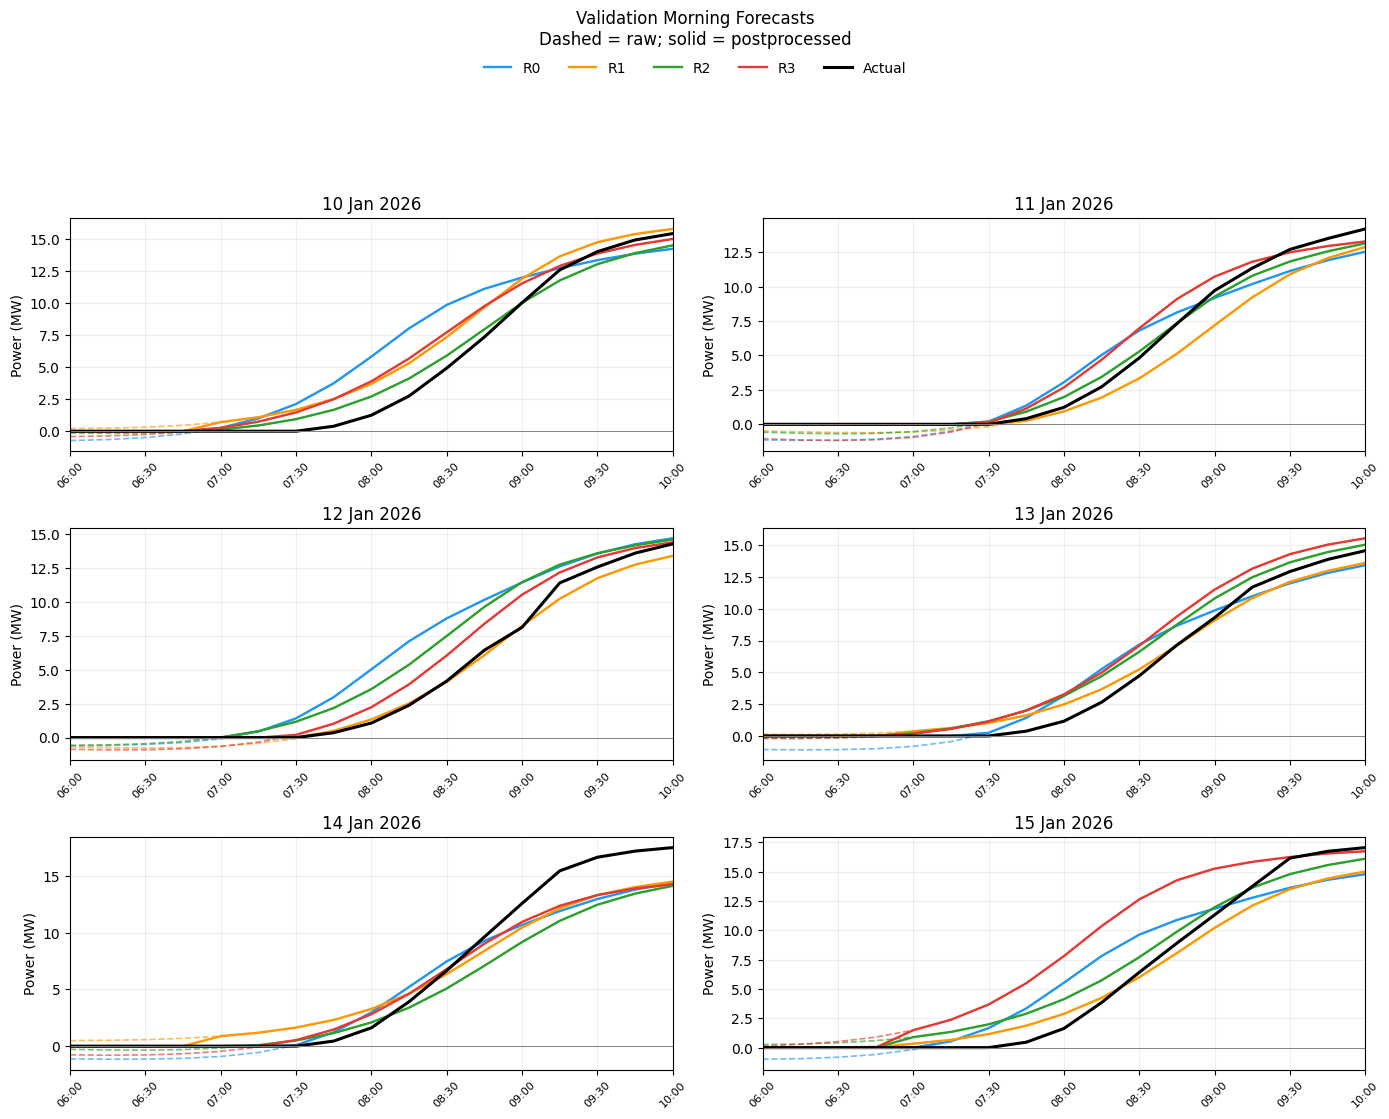

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ---------------------------------------------------------
# 1. Validation predictions in MW
# ---------------------------------------------------------
validation_predictions_scaled = model.predict(
    [X_validation_scaled, future_time_validation],
    verbose=1,
)

validation_pred_raw = target_scaler.inverse_transform(
    validation_predictions_scaled.reshape(-1, 1)
).reshape(validation_predictions_scaled.shape)

validation_actual = np.asarray(
    y_validation, dtype=np.float64
).copy()

assert validation_pred_raw.shape == validation_actual.shape
assert validation_actual.shape[1] == TARGET_LENGTH
assert np.isfinite(validation_pred_raw).all()
assert np.isfinite(validation_actual).all()

validation_pred_final = np.maximum(validation_pred_raw, 0.0)
validation_pred_final[:, night_mask] = 0.0

validation_dates = pd.DatetimeIndex(
    pd.to_datetime(dates_validation)
).normalize()

validation_labels = np.asarray(revision_labels_validation)
unique_validation_dates = validation_dates.unique().sort_values()


# ---------------------------------------------------------
# 2. Morning diagnostics across ALL validation days
# ---------------------------------------------------------
# 06:00–09:45. This window is for diagnosis only.
morning_positions = np.arange(24, 40)

# A reporting threshold, not a new clipping rule.
ACTIVITY_THRESHOLD_MW = 0.1


def first_active_position(curve):
    """First daily block exceeding the reporting threshold."""
    positions = np.flatnonzero(curve > ACTIVITY_THRESHOLD_MW)
    return int(positions[0]) if positions.size else None


summary_rows = []
daily_rows = []

for revision in REVISION_LENGTHS:
    indices = np.flatnonzero(validation_labels == revision)
    if indices.size == 0:
        continue

    actual_morning = validation_actual[indices][:, morning_positions]

    # Observed zero/near-zero morning blocks, used only for evaluation.
    near_zero_actual = (
        np.abs(actual_morning) <= ACTIVITY_THRESHOLD_MW
    )

    for prediction_name, predictions in (
        ("Raw", validation_pred_raw),
        ("Postprocessed", validation_pred_final),
    ):
        predicted_morning = predictions[indices][:, morning_positions]
        errors = predicted_morning - actual_morning

        false_positive = (
            near_zero_actual
            & (predicted_morning > ACTIVITY_THRESHOLD_MW)
        )

        summary_rows.append({
            "Revision": revision,
            "Predictions": prediction_name,
            "Morning MAE MW": np.mean(np.abs(errors)),
            "Morning bias MW": np.mean(errors),
            "Near-zero actual blocks": int(near_zero_actual.sum()),
            "False-positive blocks": int(false_positive.sum()),
            "False-positive %": (
                100.0 * false_positive.sum() / near_zero_actual.sum()
                if near_zero_actual.any() else np.nan
            ),
            "Mean positive forecast at near-zero actual MW": (
                np.maximum(
                    predicted_morning[near_zero_actual], 0.0
                ).mean()
                if near_zero_actual.any() else np.nan
            ),
            "Days with morning false positive": int(
                false_positive.any(axis=1).sum()
            ),
            "Days evaluated": len(indices),
        })

    for idx in indices:
        actual_start = first_active_position(validation_actual[idx])
        predicted_start = first_active_position(
            validation_pred_final[idx]
        )

        # Only compare morning starts; report unavailable otherwise.
        valid_start_comparison = (
            actual_start is not None
            and predicted_start is not None
            and actual_start < 48
            and predicted_start < 48
        )

        daily_rows.append({
            "Date": validation_dates[idx].date(),
            "Revision": revision,
            "Actual first active block": (
                actual_start + 1 if actual_start is not None else np.nan
            ),
            "Predicted first active block": (
                predicted_start + 1
                if predicted_start is not None else np.nan
            ),
            "Start error minutes": (
                15 * (predicted_start - actual_start)
                if valid_start_comparison else np.nan
            ),
        })


validation_morning_metrics = pd.DataFrame(summary_rows)
validation_start_diagnostics = pd.DataFrame(daily_rows)

print("\nVALIDATION MORNING ERRORS: 06:00–09:45")
print(
    validation_morning_metrics.round(3).to_string(index=False)
)

print(
    "\nFIRST ACTIVE BLOCK: postprocessed forecast versus actual\n"
    "Threshold: > 0.1 MW; negative start error = forecast starts early."
)

start_summary = (
    validation_start_diagnostics.groupby("Revision")[
        "Start error minutes"
    ]
    .agg(["count", "median", "mean"])
    .rename(columns={
        "count": "Days compared",
        "median": "Median start error min",
        "mean": "Mean start error min",
    })
)

print(start_summary.round(1).to_string())


# ---------------------------------------------------------
# 3. Plot first six validation days, selected chronologically
# ---------------------------------------------------------
plot_days = unique_validation_dates[:6]
plot_positions = np.arange(24, 41)  # 06:00–10:00 inclusive

colors = {
    "R0": "#2196F3",
    "R1": "#FF9800",
    "R2": "#2CA02C",
    "R3": "#E53935",
}

if len(plot_days):
    ncols = 2 if len(plot_days) > 1 else 1
    nrows = (len(plot_days) + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(14 if ncols == 2 else 9, 3.4 * nrows + 1),
        squeeze=False,
    )

    for ax, day in zip(axes.ravel(), plot_days):
        day_mask = np.asarray(validation_dates == day)
        day_indices = np.flatnonzero(day_mask)

        timestamps = pd.date_range(
            day, periods=TARGET_LENGTH, freq="15min"
        )
        morning_times = timestamps[plot_positions]

        for revision in REVISION_LENGTHS:
            indices = np.flatnonzero(
                day_mask & (validation_labels == revision)
            )
            assert len(indices) == 1
            idx = indices[0]

            # Dashed: model output before clipping and night masking.
            ax.plot(
                morning_times,
                validation_pred_raw[idx, plot_positions],
                color=colors[revision],
                linestyle="--",
                linewidth=1.2,
                alpha=0.65,
            )

            # Solid: forecast after existing postprocessing.
            ax.plot(
                morning_times,
                validation_pred_final[idx, plot_positions],
                color=colors[revision],
                linewidth=1.7,
                label=revision,
            )

        ax.plot(
            morning_times,
            validation_actual[day_indices[0], plot_positions],
            color="black",
            linewidth=2.2,
            label="Actual",
        )

        ax.axhline(0.0, color="gray", linewidth=0.7)
        ax.set_title(day.strftime("%d %b %Y"))
        ax.set_xticks(morning_times[::2])
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.tick_params(axis="x", rotation=45, labelsize=8)
        ax.set_xlim(morning_times[0], morning_times[-1])
        ax.set_ylabel("Power (MW)")
        ax.grid(alpha=0.2)

    for ax in axes.ravel()[len(plot_days):]:
        ax.set_visible(False)

    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.96),
        ncol=5,
        frameon=False,
    )
    fig.suptitle(
        "Validation Morning Forecasts\n"
        "Dashed = raw; solid = postprocessed",
        y=0.995,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.89])
    plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Change to "Scenario 1" in the old notebook.
SCENARIO_NAME = "Scenario 2"

BAND_FRACTION = 0.07
ACTIVE_THRESHOLD_MW = 0.1
NUMERICAL_TOLERANCE_MW = 1e-6

actual = np.asarray(y_actual, dtype=np.float64)
predicted = np.asarray(y_pred, dtype=np.float64)

assert actual.shape == predicted.shape
assert actual.ndim == 2 and actual.shape[1] == TARGET_LENGTH
assert np.isfinite(actual).all()
assert np.isfinite(predicted).all()

# Absolute width keeps bounds ordered even for negative measured values.
band_width = BAND_FRACTION * np.abs(actual)
lower_bound = actual - band_width
upper_bound = actual + band_width

inside_band = (
    (predicted >= lower_bound - NUMERICAL_TOLERANCE_MW)
    & (predicted <= upper_bound + NUMERICAL_TOLERANCE_MW)
)

rows = []

groups = {
    "Overall": np.arange(len(actual)),
    **{
        revision: np.asarray(indices, dtype=int)
        for revision, indices in revision_indices_test.items()
    },
}

for revision, indices in groups.items():
    if len(indices) == 0:
        continue

    group_actual = actual[indices]
    group_inside = inside_band[indices]

    for scope, eligible in (
        ("All blocks", np.ones(group_actual.shape, dtype=bool)),
        (
            "Active generation",
            group_actual > ACTIVE_THRESHOLD_MW,
        ),
    ):
        total = int(eligible.sum())
        inside = int((group_inside & eligible).sum())
        outside = total - inside

        rows.append({
            "Scenario": SCENARIO_NAME,
            "Revision": revision,
            "Scope": scope,
            "Evaluated blocks": total,
            "Inside ±7%": inside,
            "Outside ±7%": outside,
            "Inside band %": (
                100.0 * inside / total if total else np.nan
            ),
        })

band_metrics_df = pd.DataFrame(rows)

print(
    band_metrics_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}",
    )
)

  Scenario Revision             Scope  Evaluated blocks  Inside ±7%  Outside ±7%  Inside band %
Scenario 2  Overall        All blocks              2304        1484          820          64.41
Scenario 2  Overall Active generation              1040         275          765          26.44
Scenario 2       R0        All blocks               576         364          212          63.19
Scenario 2       R0 Active generation               260          58          202          22.31
Scenario 2       R1        All blocks               576         399          177          69.27
Scenario 2       R1 Active generation               260          99          161          38.08
Scenario 2       R2        All blocks               576         399          177          69.27
Scenario 2       R2 Active generation               260          96          164          36.92
Scenario 2       R3        All blocks               576         322          254          55.90
Scenario 2       R3 Active generation   